# FMNN25 Project 3 - Optimization

## Task 5 - Newton's method on the Rosenbrock function
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with exact linesearch.

fdiff > residual_tol 4.6686584065678013e-14
xdiff > cauchy_tol 2.688508850965496e-07
Computed minimum: [1. 1.]
f(x): 1.4750165579248397e-25
Iterations: 11


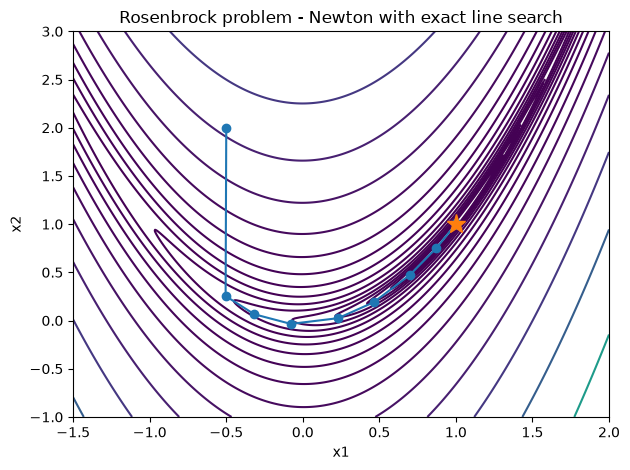

In [4]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithLineSearchMethod, \
                                           test_exact_linesearch


method = NewtonWithLineSearchMethod(rosenbrock_problem)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton with exact line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 7 - Minimizing the Rosenbrock function with inexact line search
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with an inexact linesearch.

Here, using Powell-Wolfe conditions following the algorithm presented in the course lecture.

fdiff > residual_tol 3.780331451884033e-09
Computed minimum: [1. 1.]
f(x): 1.4372463115940511e-15
Iterations: 16


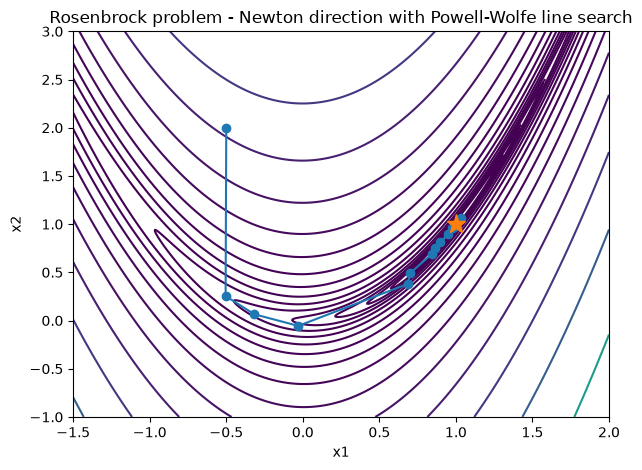

In [6]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithPowellWolfe, \
                                           test_exact_linesearch

# Note: implementation here uses lecture's notation and algorithm.
# Fletcher's book uses swapped sigma and rho.
method = NewtonWithPowellWolfe(rosenbrock_problem, sigma=0.01, rho=0.1, alpha_start=1.0)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton direction with Powell-Wolfe line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 11

Compare our implemented optimization methods and the scipy implemented BFGS on the Chebyquad problem.

In [5]:
import scipy
import numpy as np
from optproblem_class import OptProblem
from chebyquad_problem import chebyquad, gradchebyquad
from quasinewton_methods import BFGS, DFP, SymmetricBroyden, BadBroyden, GoodBroyden
from newtons_and_linesearch_methods import NewtonsMethod, NewtonWithLineSearchMethod, NewtonWithPowellWolfe

for n in (4,8,11):
    prob = OptProblem(
        chebyquad,
        input_shape=n,
        grad=gradchebyquad
    )
    method_kwargs = {
        "prob": prob,
        "verbose": False
    }

    methods = {
        "Good Broyden" : GoodBroyden(**method_kwargs),
        "Bad Broyden" : BadBroyden(**method_kwargs),
        "Symmetric Broyden" : SymmetricBroyden(**method_kwargs),
        "DFP" : DFP(**method_kwargs),
        "BFGS" : BFGS(**method_kwargs),
        "Newton" : NewtonsMethod(**method_kwargs),
        "Newton exact linesearch" : NewtonWithLineSearchMethod(**method_kwargs),
        "Newton Powell-Wolfe linesearch": NewtonWithPowellWolfe(
                                            sigma=0.01,
                                            rho=0.1,
                                            alpha_start=1.0,
                                            **method_kwargs)
    }

    x0 = np.linspace(0,1,n)

    solve_kwargs = {
        "x0" : x0,
        "residual_tol" : 1e-8,
        "cauchy_tol" : 1e-5,
        "max_steps" : 20
    }

    solutions = {k:m.solve(**solve_kwargs) for k,m in methods.items()}

    # include scipy bfgs:
    solutions["scipy BFGS"] = scipy.optimize.fmin_bfgs(
        prob.f,
        x0,
        fprime=prob.grad,
        disp=False,
        maxiter=500
        )

    print("\n"*3 + "*"*40)
    print("*"*10 + f"{f' Done with n={n}!':^20}" + "*"*10)
    print("*"*40 + "\n"*2)

    print("\n\n".join((
                      f"{k}," +\
                      (f"\nIterations: {methods[k].steps}" if k in methods else "") +\
                      (f"\nExecution Time (s): {sum(methods[k].exec_time_history)*10**-9:.5f}" if k in methods else "") +\
                      f"\nf: {prob(x)}," +\
                      f"\nx: {x}"
                      ) for k,x in solutions.items()))




****************************************
**********   Done with n=4!   **********
****************************************


Good Broyden,
Iterations: 1
Execution Time (s): 0.00084
f: 6.757957461040579e-21,
x: [0.88729833 0.62909944 0.37090056 0.11270167]

Bad Broyden,
Iterations: 1
Execution Time (s): 0.00099
f: 6.757957461040579e-21,
x: [0.88729833 0.62909944 0.37090056 0.11270167]

Symmetric Broyden,
Iterations: 1
Execution Time (s): 0.00103
f: 6.757957461040579e-21,
x: [0.88729833 0.62909944 0.37090056 0.11270167]

DFP,
Iterations: 1
Execution Time (s): 0.00091
f: 6.757957461040579e-21,
x: [0.88729833 0.62909944 0.37090056 0.11270167]

BFGS,
Iterations: 1
Execution Time (s): 0.00070
f: 6.757957461040579e-21,
x: [0.88729833 0.62909944 0.37090056 0.11270167]

Newton,
Iterations: 1
Execution Time (s): 0.00051
f: 0.011012049050596056,
x: [0.08333332 0.36111113 0.63888887 0.91666668]

Newton exact linesearch,
Iterations: 1
Execution Time (s): 0.00117
f: 2.380469274533698e-24,
x: [0.1

## Task 12

Study the approximation quality of the BFGS method's estimated inverse Hessian.